# 00 Review recording clocks

Run this before May 31 profile preparation. It inspects original detector and logger recordings,
reports clock issues, and saves plots. It **does not synchronize clocks, pair particle events,
train a model, or verify UTC**. The same checks can be run on simultaneous lead-box ground data.
Use Python (HERA). Original files remain unchanged.


In [1]:
from pathlib import Path
import sys, json
import pandas as pd
from IPython.display import display, Image
here = Path.cwd().resolve()
ROOT = next((p for p in (here, *here.parents)
             if (p / "src/review_clocks.py").is_file()
             and (p / "src/prepare_profiles.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Copy the supplied src files into your repository and open this notebook in notebooks/.")
sys.path.insert(0, str(ROOT / "src"))
import review_clocks
print("Project:", ROOT)
print("Python:", sys.executable)


Project: C:\Users\gunja\Documents\Hera\HERA-Machine-Learning
Python: C:\Users\gunja\Documents\Hera\HERA-Machine-Learning\.venv\Scripts\python.exe


## Choose this recording

Existing per-detector configs are used when present; otherwise the files below are searched for
in DATA_DIR and its RawData/ subfolder. Verify the printed paths before running the review.
For ground data, change RUN_ID and provide the actual simultaneous recordings in FILE_OVERRIDES.
Do not use unrelated recordings collected on different days.

The rollover period below is a **candidate** inherited from the earlier investigation, not a
confirmed firmware specification. The 30-second bound permits a sparse event logger to wrap
between records; it does not grant a 30-second coincidence window or establish synchronization.


In [2]:
RUN_ID = "ground_run_01"
DETECTORS = ["top", "mid", "bot"]
DATA_DIR = ROOT / "raw" / RUN_ID

BIN_SECONDS = 60.0  # Overview plots only; original event times stay unchanged.

# Provisional assumptions to check against this recording:
ROLLOVER_SECONDS_CANDIDATE = 4294.967296
ROLLOVER_MAX_GAP_SECONDS_CANDIDATE = 30.0

LOGGER_COUNTER_COLUMNS = [
    "Events CW1&2",
    "Events CW1&2&3",
]

FILE_OVERRIDES = {
    "top": DATA_DIR / "top.txt",
    "mid": DATA_DIR / "mid.txt",
    "bot": DATA_DIR / "bot.txt",
    "logger": DATA_DIR / "AHD038.csv",
}


In [3]:
def resolve_path(value):
    p = Path(value)
    return (p if p.is_absolute() else ROOT / p).resolve()

def find_input(name):
    matches = [p for p in (DATA_DIR / name, DATA_DIR / "RawData" / name) if p.is_file()]
    if len(matches) != 1:
        raise FileNotFoundError(f"Expected exactly one {name!r} under {DATA_DIR} or RawData/. Set FILE_OVERRIDES.")
    return matches[0].resolve()

if not DETECTORS or len(DETECTORS) != len(set(DETECTORS)):
    raise ValueError("Choose distinct detector identities.")
default_names = {"left": "left_AxLab_M_038.txt", "middle": "middle_AxLab_M_037 copy.txt",
                 "right": "right_AxLab_M_038 copy.txt"}
detector_files, logger_candidates = {}, []
for detector in DETECTORS:
    config_path = ROOT / "configs" / f"{RUN_ID}_{detector}.json"
    cfg = json.loads(config_path.read_text(encoding="utf-8")) if config_path.is_file() else None
    if cfg is not None and (cfg["flight_id"], cfg["detector_id"]) != (RUN_ID, detector):
        raise ValueError(f"Configuration identity mismatch: {config_path}")
    if detector in FILE_OVERRIDES:
        detector_files[detector] = resolve_path(FILE_OVERRIDES[detector])
    elif cfg is not None:
        detector_files[detector] = resolve_path(cfg["detector_file"])
    elif detector in default_names:
        detector_files[detector] = find_input(default_names[detector])
    else:
        raise ValueError(f"Provide FILE_OVERRIDES for detector {detector}.")
    if cfg is not None:
        logger_candidates.append(resolve_path(cfg["logger_file"]))
if "logger" in FILE_OVERRIDES:
    logger_file = resolve_path(FILE_OVERRIDES["logger"])
elif logger_candidates:
    if len(set(logger_candidates)) != 1:
        raise ValueError("The selected detectors reference different logger files; review separately.")
    logger_file = logger_candidates[0]
else:
    logger_file = find_input("AHD011 copy.csv")
all_inputs = {**detector_files, "logger": logger_file}
for name, path in all_inputs.items():
    if not path.is_file(): raise FileNotFoundError(f"{name}: {path}")
display(pd.DataFrame([{"device": n, "original_file": str(p), "size_MiB": p.stat().st_size/2**20}
                      for n,p in all_inputs.items()]))


,device,original_file,size_MiB
0,top,C:\Users\gunja\Documents\Hera\HERA-Machine-Lea...,204.738310
1,mid,C:\Users\gunja\Documents\Hera\HERA-Machine-Lea...,212.879601
2,bot,C:\Users\gunja\Documents\Hera\HERA-Machine-Lea...,192.610279
3,logger,C:\Users\gunja\Documents\Hera\HERA-Machine-Lea...,198.949523


## Run diagnostic review

Strict input checks stop on detector timestamp/event discontinuities, counter decreases, or logger
reversals inconsistent with the candidate rollover rule. Do not suppress an error or expand a
threshold just to obtain a clean plot. Investigate the records and document any revised rule.
The logger's candidate unwrapped timer is for inspection only; it is not a detector or UTC mapping.


In [4]:
report, clock_summary, RUN_DIR = review_clocks.review(
    ROOT, detector_files, logger_file, RUN_ID, bin_seconds=BIN_SECONDS,
    rollover_seconds_candidate=ROLLOVER_SECONDS_CANDIDATE,
    rollover_max_gap_seconds_candidate=ROLLOVER_MAX_GAP_SECONDS_CANDIDATE,
    logger_counter_columns=LOGGER_COUNTER_COLUMNS)
print("Diagnostic outputs:", RUN_DIR)
display(clock_summary)
display(pd.read_csv(RUN_DIR / "logger_rollovers.csv"))
print("Recorded date/time issues:", report["datetime_review"])
print("Source files unchanged:", report["source_hashes_unchanged"])
print("Clock synchronization performed:", report["clock_corrections_applied"])


Diagnostic outputs: C:\Users\gunja\Documents\Hera\HERA-Machine-Learning\results\ground_run_01\20261116T052307023478Z_clock_review


,device,rows,first_event,last_event,first_timer_s,last_timer_s,recorded_span_hours,backward_timer_steps,maximum_interevent_gap_s,flagged_coincidence_events,coincidence_flag_status,initial_pressure_median_pa
0,top,3909912,1.0,3909912.0,0.231435,697456.731879,193.737917,0,3.509805,0.0,all_zero_interpretation_unverified,101681.0
1,mid,4085008,1.0,4085008.0,0.012712,697456.566498,193.737932,0,2.402999,0.0,all_zero_interpretation_unverified,100744.0
2,bot,3678007,1.0,3678007.0,0.074314,697458.814682,193.738539,0,2.706328,0.0,all_zero_interpretation_unverified,101628.0
3,logger,1215921,NaN,NaN,7.391601,60469.661132,16.795075,14,NaN,NaN,NaN,NaN


,source_record,source_csv_row,before_timer_s,after_timer_s,candidate_gap_s
0,90014,90015,4294.927734,0.029774,0.069336
1,178418,178419,4294.962391,0.052712,0.057617
2,265330,265331,4294.884743,0.029752,0.112305
3,351541,351542,4294.953580,0.074175,0.087891
4,436850,436851,4294.912066,0.008246,0.063476
5,522499,522500,4294.959418,0.033138,0.041016
6,607731,607732,4294.966731,0.149826,0.150391
7,693191,693192,4294.937912,0.024327,0.053711
8,778800,778801,4294.964757,0.024804,0.027343
9,864589,864590,4294.960351,0.033094,0.040039


Recorded date/time issues: {'available': True, 'unparsed_datetimes': 0, 'backward_datetime_steps': 50270, 'large_backward_jumps_possible_stale_date': 2, 'distinct_recorded_dates': 1, 'timezone_verified': False}
Source files unchanged: True
Clock synchronization performed: False


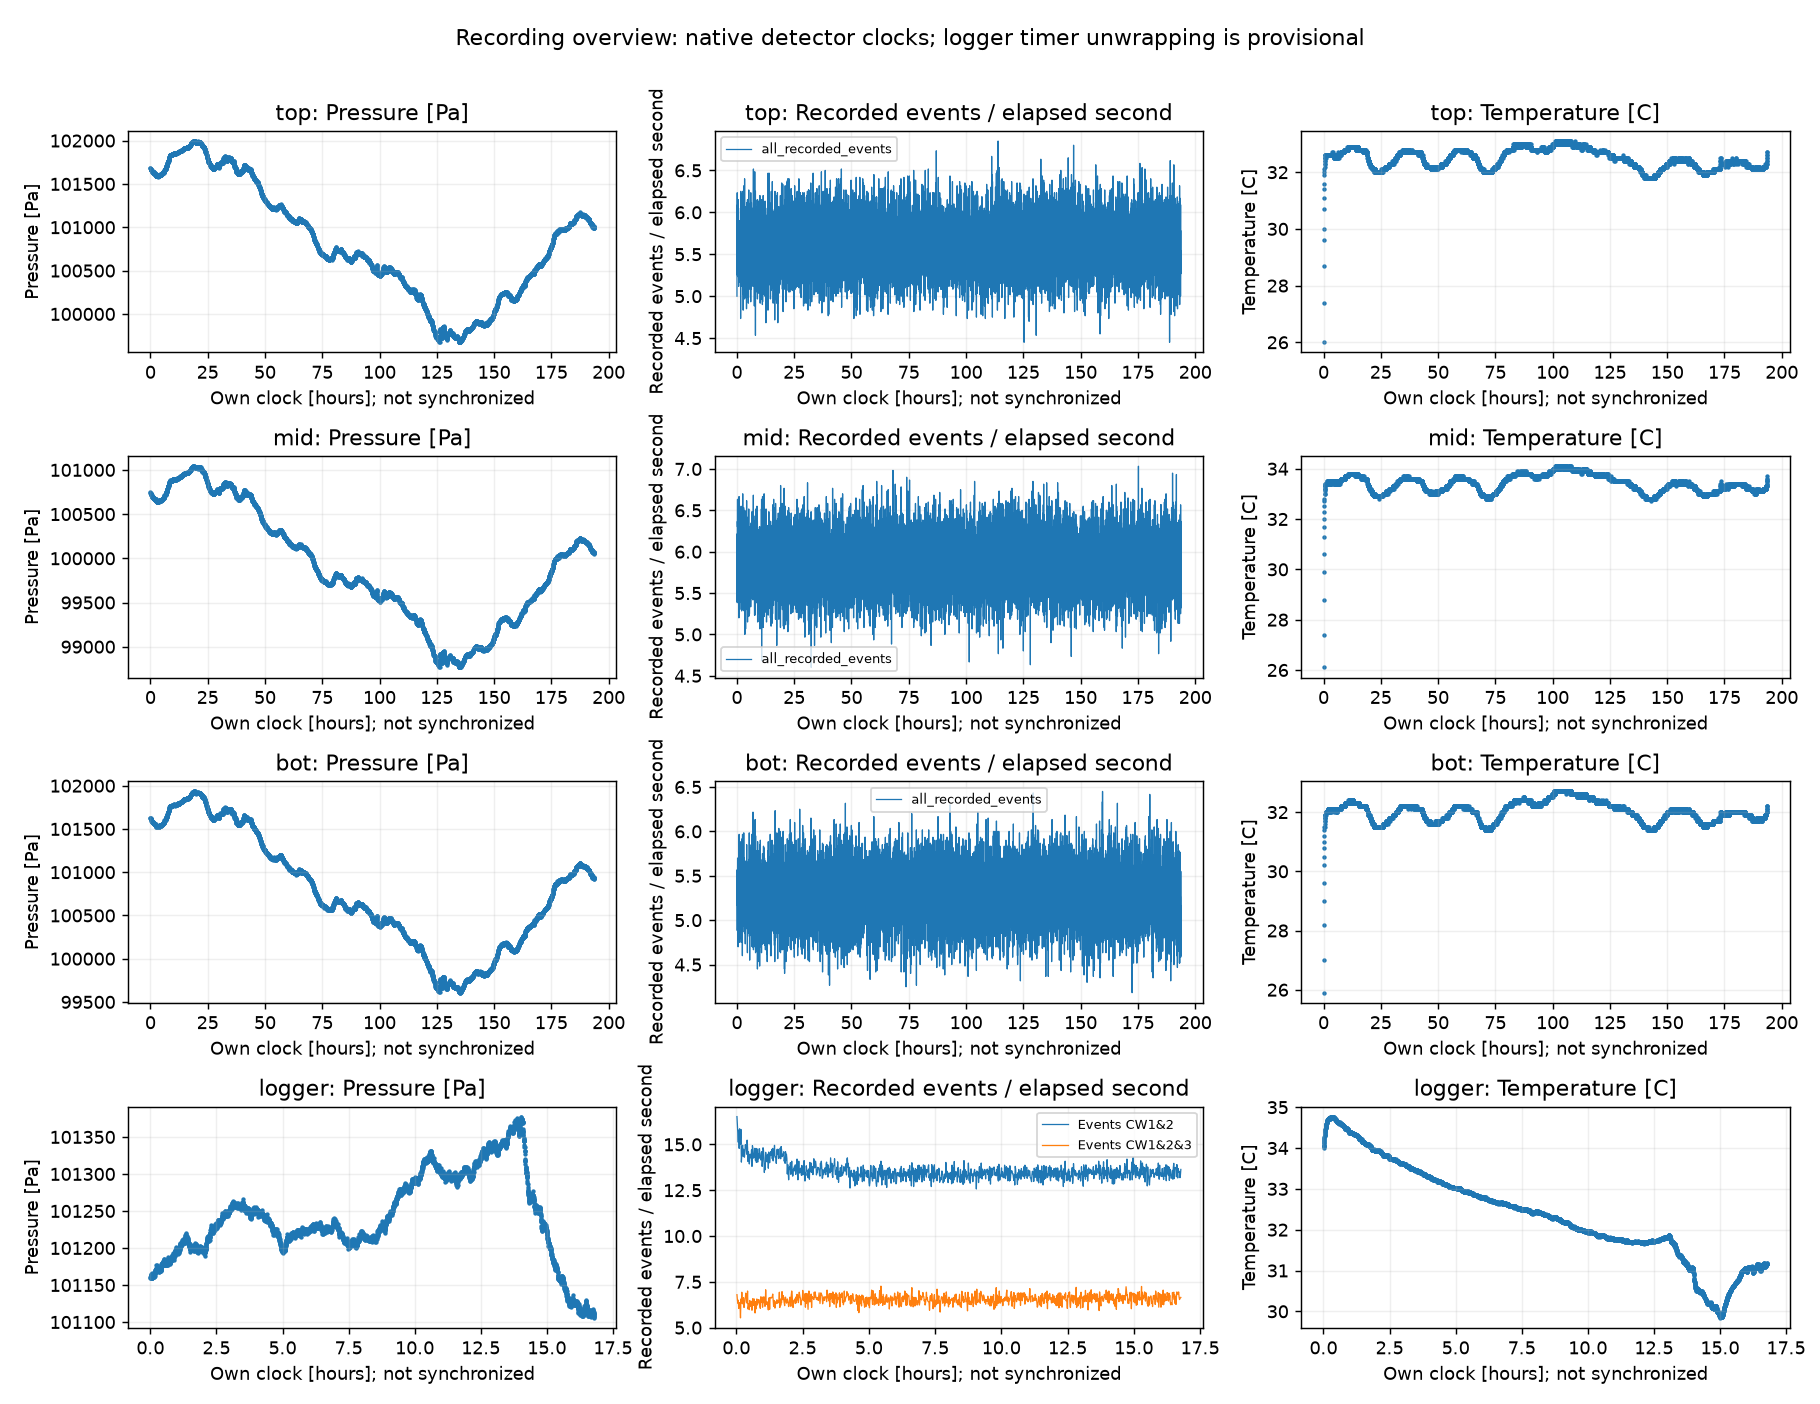

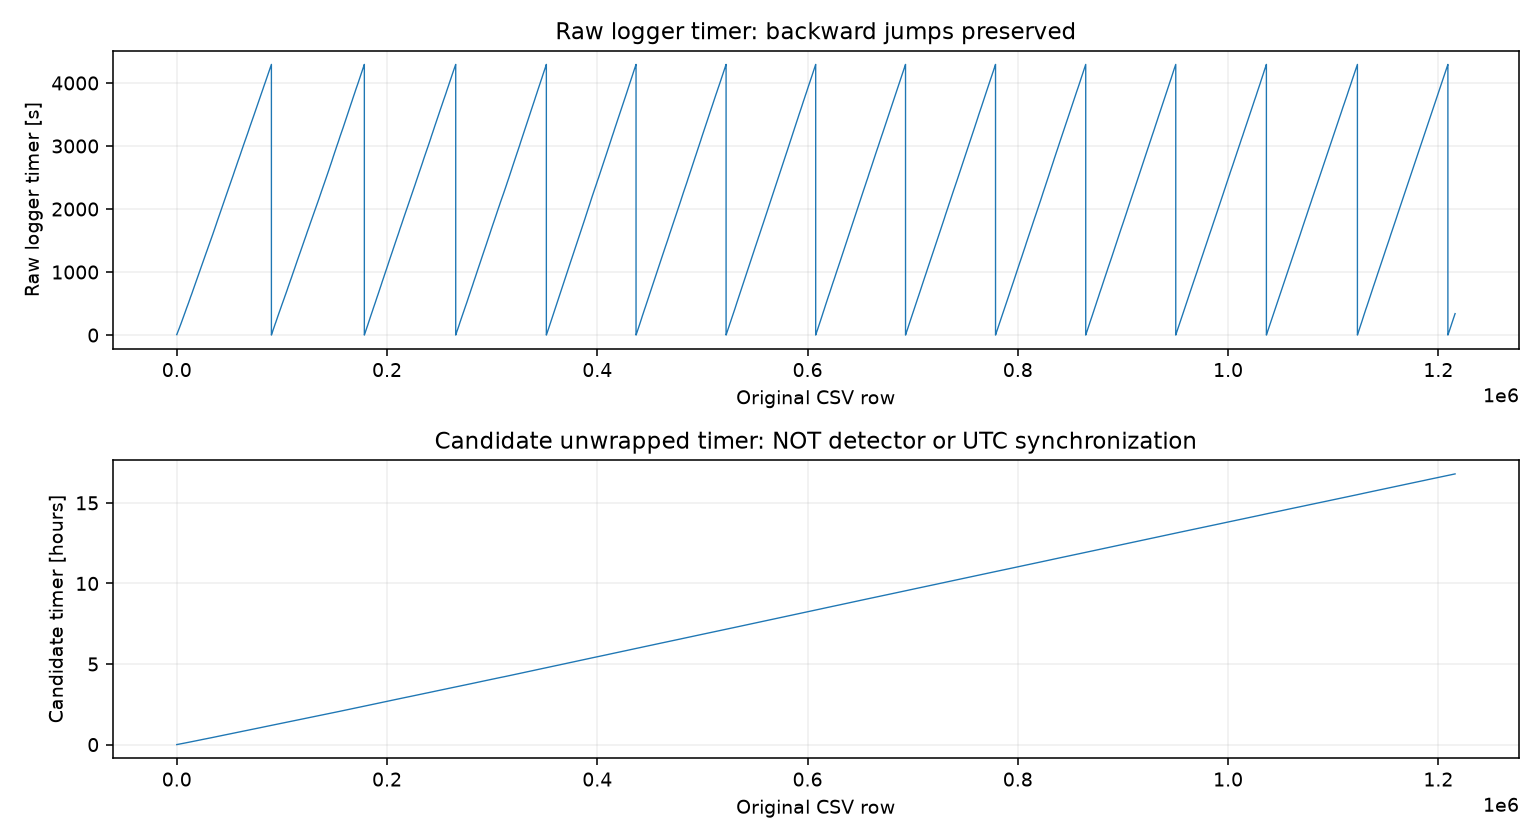

Date/time issues (first 10):


,source_csv_row,issue,date_recorded,rtc_recorded,step_seconds
0,10,backward_datetime_step,8/10/2026,21:6:59.759,-0.211
1,22,backward_datetime_step,8/10/2026,21:7:00.697,-0.112
2,57,backward_datetime_step,8/10/2026,21:7:01.621,-0.415
3,83,backward_datetime_step,8/10/2026,21:7:02.737,-0.943
4,89,backward_datetime_step,8/10/2026,21:7:02.615,-0.349
5,106,backward_datetime_step,8/10/2026,21:7:03.615,-0.322
6,142,backward_datetime_step,8/10/2026,21:7:04.615,-0.616
7,165,backward_datetime_step,8/10/2026,21:7:05.647,-0.361
8,194,backward_datetime_step,8/10/2026,21:7:06.662,-0.419
9,218,backward_datetime_step,8/10/2026,21:7:07.639,-0.509


In [5]:
for filename in ["recording_overview.png", "logger_timer_review.png"]:
    display(Image(filename=str(RUN_DIR / filename), width=1100))
issues = pd.read_csv(RUN_DIR / "logger_datetime_issues.csv")
print("Date/time issues (first 10):")
display(issues.head(10))


## Interpretation

- Counts from each device remain on that device's own elapsed clock. Start/end times are not assumed simultaneous.
- The all-zero detector coincidence flags mean the field supplies no usable coincidence selection; they do not prove absence of shared particles.
- Logger channel rates are different targets from detector all-event rates. Similar curves do not establish correct event pairing.
- A candidate continuous logger timer does not verify its speed or its correspondence to UTC.
- Pressure sensors can have different offsets. Do not force identical pressure values to define exact timing.
- Quiet event intervals do not establish downtime. Rates here assume continuous acquisition inside complete bins.

For a team review, share clock_summary.csv, logger_rollovers.csv, clock_review_report.json and the
 two PNGs. Keep the source file hashes and exact settings with the results.


## Next stage for synchronization

1. Reproduce the existing team alignment as a baseline using its exact code version and parameters.
2. Identify candidate shared events or independently known timing markers. Record how correspondences were established.
3. Fit a simple offset plus clock-speed correction first; consider separate segments only if diagnostics justify them.
4. Test on time blocks or markers excluded from fitting. Compare with a constant shift and deliberately wrong time shifts to estimate accidental matches.
5. Use a smooth drift model only if it improves these checks. This is a separate timing model, not the radiation-count GAM.

Stationary lead-box data is valuable if the detectors recorded simultaneously and share some events
or timing markers. Constant background rates or flat pressure alone cannot identify drift. Ground
corrections must not be copied to flight: clock starts and operating temperatures can differ.

For May 31 profiles, run notebook 01 with its own three configs and reviewed native-clock phase
boundaries. Notebooks 02/03 can then fit/validate preliminary all-event profiles using each detector's
own pressure. Their scores do not validate clock synchronization. Do not force physical peak alignment.

Before committing, clear outputs and save. Generated results and original data stay outside Git.
